In [1]:
%matplotlib widget

In [10]:
%%html
<style>
.cell-output-ipywidget-background {
   background-color: transparent !important;
}
.jp-OutputArea-output {
   background-color: transparent;
}  
</style>

In [11]:
import os
import sys
import numpy as np
import torch
import pandas as pd
import pickle
import matplotlib.pyplot as plt

root = os.path.dirname(os.path.dirname(os.path.realpath('__file__')))
sys.path.insert(0, os.path.join(root, 'experiments_bridge'))
from ponte_utils import estimate_spectrum, MSISSD

root = os.path.dirname(os.path.dirname(os.path.realpath('__file__')))
sys.path.insert(0, os.path.join(root, 'src'))
from dataset import dataset_dir
from detectors import detectors_dir
from models import models_dir
results_folder = '/srv/newpenny/dnn-cs/tsoc/results/TSOC/detection'

from wombats.detectors.gaussian_distribution_based import *


from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

from ray import tune

from scipy.fft import dct
from scipy import linalg

from cs import CompressedSensing, generate_sensing_matrix
from cs.decoders import BasisPursuitDenoise
from models.tsoc import TSOC as TSOC
from models.tsoc_v2 import TSOC as TSOC2
from models.tsoc_v3 import TSOC as TSOC3
from cs.utils import compute_rsnr

import cmasher as cmr
cmap_auc = cmr.get_sub_cmap('brg', 0, 1)

In [12]:
def support_estimator(method='random_forest', scale=True):
    if method=='random_forest':
        model = RandomForestClassifier(n_estimators=100, max_depth=10)
    elif method=='logistic_regression':
        model = LogisticRegression(
            penalty='l2',    # L2 regularization
            solver='lbfgs', #'lbfgs', liblinear,  Optimizer (supports multi-label classification)
            max_iter=500,    # Increase iterations to ensure convergence
            verbose=0
        )
    elif method=='SVM':
        model = SVC(kernel='poly', probability=True)
    elif method=='naive_bayes':
        model = GaussianNB()
    elif method=='Sparse SVM':
        model = LinearSVC(penalty='l1', dual=False, max_iter=100_000)
    elif method=='k_neighbors':
        model = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
    elif method=='radius_neighbors':
        model = RadiusNeighborsClassifier(radius=1.0, metric='euclidean')

    model = MultiOutputClassifier(model)
    if scale:
        model = make_pipeline(
        StandardScaler(),
        model
        )
    return model


In [13]:
def train_pred(cs, A, B, Y_train, Y_test, Z_train, source='Y', method='random_forest', scale=True):
    estimator = support_estimator(method=method, scale=scale)
    if source == 'Y':
        XYZ_train = Y_train.copy()
        XYZ_test = Y_test.copy()
    elif source == 'Y@A':
        XYZ_train = Y_train @ A
        XYZ_test = Y_test @ A
    elif source == 'Y@B':
        XYZ_train = Y_train @ B
        XYZ_test = Y_test @ B
    estimator.fit(XYZ_train, Z_train.astype(int))
    
    Zhat = estimator.predict(XYZ_test)

    Xhat = np.zeros(Zhat.shape)

    idx = Zhat.sum(axis=-1) > 0
    Xhat[idx] = cs.decode(list(zip(Y_test[idx], Zhat[idx].astype(bool))))
    return Zhat, Xhat

In [14]:
n = 300
fs = 50
seed_data = 0
seed_matrix = 0
seed_training = 0
window_size = 20
fraction = 100
method = 'TSOC'
m = 50
orth = True
mode = 'rakeness'
processes=48
K = 1
M = 100

gpu = 0
optimizer = "adam"
lr = 0.001
batch_size = 64
min_lr = 0.00001
orthogonal = True
source = 'best'
alpha = 0.5
train_fraction = 0.9
factor = 0.2
min_delta = 1e-5
patience = 40
epochs = 1000
threshold = 0.5

In [15]:
detector_modes = ['sparsity', 'self-assessment', 'self-assessment-complement-MD',
                      'self-assessment-complement-MDy', 'self-assessment-complement-MD-CDF']

In [16]:
files_dir = os.path.join(dataset_dir, f'bridge_n={n}_fs={fs}_seed={seed_data}')

data_path = os.path.join(files_dir, f'bridge_train_n={n}_fs={fs}_ws={window_size}_seed={seed_data}.pkl')
with open(data_path, 'rb') as f:
    X_train = pickle.load(f)  

data_path = os.path.join(files_dir, f'bridge_train_n={n}_fs={fs}_ws={window_size}_fraction={fraction}_seed={seed_data}.pkl')
with open(data_path, 'rb') as f:
    X_train_augmented = pickle.load(f)  

data_name = f'bridge_ok_n={n}_fs={fs}_ws={window_size}_seed={seed_data}'
data_path = os.path.join(files_dir, data_name+'.pkl')
with open(data_path, 'rb') as f:
    X_test = pickle.load(f)

data_name = f'bridge_ko_n={n}_fs={fs}_ws={window_size}_seed={seed_data}'
data_path = os.path.join(files_dir, data_name+'.pkl')
with open(data_path, 'rb') as f:
    X_ko = pickle.load(f)

In [17]:
if source == 'best':
    fname =f'matrices_ort={orth}_mode={mode}_M={M}_m={m}_mode={mode}_seed={seed_data}'
    path = os.path.join(files_dir, f'Best_sensing_matrices', fname+'.pkl')
    with open(path, 'rb') as f:
        A_dict = pickle.load(f)
    A = A_dict[seed_matrix]['matrix']
    seed_matrix = A_dict[seed_matrix]['seed']

In [18]:
C_augmented = (X_train_augmented.T @ X_train_augmented) / len(X_train_augmented)
C_train = (X_train.T @ X_train) / len(X_train)
C_test = (X_test.T @ X_test) / len(X_test)




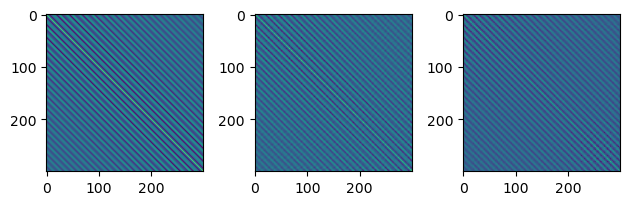

In [23]:
fig, ax = plt.subplots(1, 3)
ax[0].imshow(C_augmented)
ax[1].imshow(C_train)
ax[2].imshow(C_test)
fig.tight_layout()

In [20]:
supports_name_ = f'supports_method={method}_mode={mode}_m={m}_orth={orth}'
supports_path = os.path.join(files_dir, f'bridge_train_{supports_name_}_ws={window_size}_seed_matrix={seed_matrix}_seed_data={seed_data}.pkl')
with open(supports_path, 'rb') as f:
    Z_train = pickle.load(f)  

supports_path = os.path.join(files_dir, f'bridge_train_{supports_name_}_ws={window_size}_fraction={fraction}_seed_matrix={seed_matrix}_seed_data={seed_data}.pkl')
with open(supports_path, 'rb') as f:
    Z_train_augmented = pickle.load(f)  

supports_path = os.path.join(files_dir, f'bridge_ok_{supports_name_}_seed_matrix={seed_matrix}_seed_data={seed_data}.pkl')
with open(supports_path, 'rb') as f:
    Z_test = pickle.load(f)  

In [21]:
np.sum(Z_train_augmented, axis=-1).mean(), np.sum(Z_train, axis=-1).mean(), np.sum(Z_test, axis=-1).mean()

(20.489654692286273, 20.656349206349205, 19.751587301587303)

In [22]:
C = (X_train.T @ X_train) / len(X_train)
loc = np.trace(C @ C) / np.trace(C)**2 - 1 / n
D = dct(np.eye(n), axis=0, norm='ortho')
A = generate_sensing_matrix((m, n), mode=mode, orthogonal=orth, correlation=C, loc=loc, seed=seed_matrix)
B = A @ D
cs = CompressedSensing(A, D=D, decoder='SO')
Y_train = cs.encode(X_train)
Y_train_augmented = cs.encode(X_train_augmented)
Y_test = cs.encode(X_test)
Y_ko = cs.encode(X_ko)

In [24]:
Xhat_oracle = cs.decode(list(zip(Y_test, Z_test)))
np.mean(compute_rsnr(X_test, Xhat_oracle))

2.9243651928929055

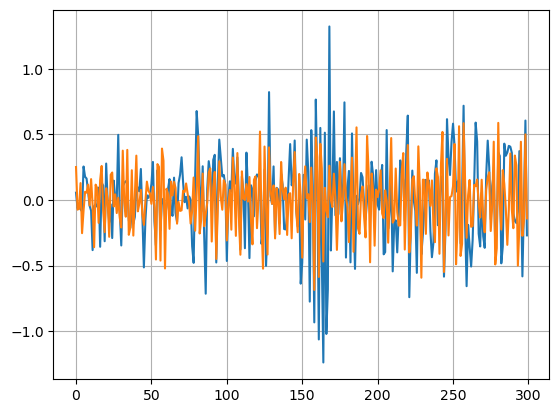

In [25]:
fig, ax = plt.subplots()
ax.plot(X_test[0])
ax.plot(Xhat_oracle[0])
ax.grid()

In [26]:
device = torch.device(f'cuda:{gpu}' if torch.cuda.is_available() else 'cpu')
tsoc = TSOC(n, m)
tsoc.to(device) # move the network to GPU
model_name = f'bridge-TSOC-N={len(X_train_augmented)}_n={n}_ws={window_size}_fraction={fraction}_m={m}_fs={fs}_mode={mode}'\
                f'_src={source}_ort={orthogonal}_epochs={epochs}_bs={batch_size}_opt={optimizer}_lr={lr}'\
                f'_th={threshold}_tf={train_fraction}_minlr={min_lr}_p={patience}'\
                f'_mind={min_delta}_seedtraining={seed_training}_seedmatrix={seed_matrix}_seeddata={seed_data}'
model_path = os.path.join(f'{models_dir}TSOC', f'alpha={alpha}', f'{model_name}.pth')
tsoc.load_state_dict(torch.load(model_path, weights_only=True))
tsoc.eval()     # Set the model to evaluation mode


TSOC(
  (fc1): Linear(in_features=50, out_features=600, bias=True)
  (fc2): Linear(in_features=600, out_features=600, bias=True)
  (fc3): Linear(in_features=600, out_features=300, bias=True)
  (fc4): Linear(in_features=300, out_features=300, bias=True)
)

In [27]:

tsoc2 = TSOC2(n)
tsoc2.to(device) # move the network to GPU
model_name2 = f'bridge-TSOCv2-N={len(X_train_augmented)}_n={n}_ws={window_size}_fraction={fraction}_m={m}_fs={fs}_mode={mode}'\
                f'_src={source}_ort={orthogonal}_epochs={epochs}_bs={batch_size}_opt={optimizer}_lr={lr}'\
                f'_th={threshold}_tf={train_fraction}_minlr={min_lr}_p={patience}'\
                f'_mind={min_delta}_seedtraining={seed_training}_seedmatrix={seed_matrix}_seeddata={seed_data}'
model_path = os.path.join(f'{models_dir}TSOC', f'alpha={alpha}', f'{model_name2}.pth')
tsoc2.load_state_dict(torch.load(model_path, weights_only=True))
tsoc2.eval()     # Set the model to evaluation mode

TSOC(
  (fc1): Linear(in_features=300, out_features=300, bias=True)
  (fc2): Linear(in_features=300, out_features=300, bias=True)
  (fc3): Linear(in_features=300, out_features=300, bias=True)
)

1.701681765439459


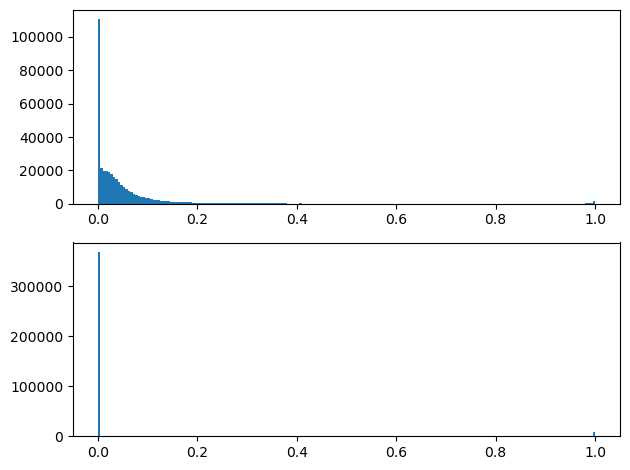

In [28]:
O_tsoc = tsoc(torch.from_numpy(Y_test).float().to(device))
O_tsoc = O_tsoc.cpu().detach().numpy() 
# 
Zhat = O_tsoc > threshold
Xhat_tsoc = np.zeros(Zhat.shape)
idx_tsoc = Zhat.sum(axis=-1) > 0
Xhat_tsoc[idx_tsoc] = cs.decode(list(zip(Y_test[idx_tsoc], Zhat[idx_tsoc])))
print(np.mean(compute_rsnr(X_test, Xhat_tsoc)))

fig, ax = plt.subplots(2, 1)
ax[0].hist(O_tsoc.flatten(), bins=200)
ax[1].hist(Zhat.astype(int).flatten(), bins=200)
fig.tight_layout()

In [29]:
np.sum(Zhat, axis=-1).mean()

7.565873015873016

1.7562234523905895


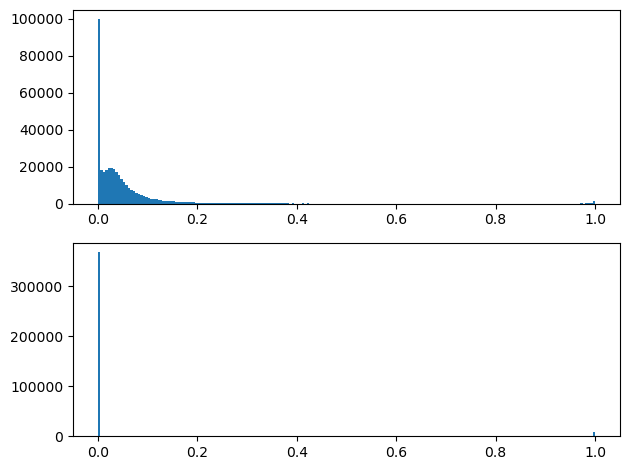

In [30]:
O_tsoc2 = tsoc2(torch.from_numpy(Y_test @ B).float().to(device))
O_tsoc2 = O_tsoc2.cpu().detach().numpy() 
# Zhat = O > threshold
Zhat = O_tsoc2 > threshold
Xhat_tsoc2 = np.zeros(Zhat.shape)
idx_tsoc2 = Zhat.sum(axis=-1) > 0
Xhat_tsoc2[idx_tsoc2] = cs.decode(list(zip(Y_test[idx_tsoc2], Zhat[idx_tsoc2])))
print(np.mean(compute_rsnr(X_test, Xhat_tsoc2)))

fig, ax = plt.subplots(2, 1)
ax[0].hist(O_tsoc2.flatten(), bins=200)
ax[1].hist(Zhat.astype(int).flatten(), bins=200)
fig.tight_layout()

In [31]:
# Zhat_rf, Xhat_rf = train_pred(cs, A, B, Y_train, Y_test, Z_train, 'Y@B', 'random_forest')
# np.mean(compute_rsnr(X_test, Xhat_rf))

In [32]:
# # random_forest = support_estimator(method='random_forest', scale=True)
# random_forest = RandomForestClassifier(n_estimators=100, max_depth=10)
# random_forest = MultiOutputClassifier(random_forest)
# random_forest = make_pipeline(
#         StandardScaler(),
#         random_forest)
# random_forest.fit(Y_train @ B, Z_train.astype(int))
# Zhat_rf = random_forest.predict(Y_test @ B)

# Xhat_rf = np.zeros(Zhat_rf.shape)

# idx = Zhat_rf.sum(axis=-1) > 0
# Xhat_rf[idx] = cs.decode(list(zip(Y_test[idx], Zhat_rf[idx].astype(bool))))

# np.mean(compute_rsnr(X_test, Xhat_rf))

In [33]:
# # random_forest = support_estimator(method='random_forest', scale=True)
# random_forest = RandomForestClassifier(n_estimators=100, max_depth=10)
# random_forest = MultiOutputClassifier(random_forest)
# random_forest = make_pipeline(
#         StandardScaler(),
#         random_forest)
# random_forest.fit(Y_train, Z_train.astype(iant))
# Zhat_rf = random_forest.predict(Y_test)

# Xhat_rf = np.zeros(Zhat_rf.shape)

# idx = Zhat_rf.sum(axis=-1) > 0
# Xhat_rf[idx] = cs.decode(list(zip(Y_test[idx], Zhat_rf[idx].astype(bool))))

# np.mean(compute_rsnr(X_test, Xhat_rf))

In [34]:
n_estimators = 100
model_name_rf = f'bridge-random_forest-ne_{n_estimators}-N={len(X_train)}_n={n}_ws={window_size}_fraction={fraction}_m={m}_fs={fs}_mode={mode}'\
                 f'_src={source}_ort={orthogonal}_th={threshold}_seedtraining={seed_training}_seedmatrix={seed_matrix}_seeddata={seed_data}'
model_path_rf = os.path.join(models_dir, 'random_forest', f'{model_name_rf}.pkl')

with open(model_path_rf, 'rb') as f:
    random_forest = pickle.load(f)

Zhat_rf = random_forest.predict(Y_test @ B)

Xhat_rf = np.zeros(Zhat_rf.shape)

idx = Zhat_rf.sum(axis=-1) > 0
Xhat_rf[idx] = cs.decode(list(zip(Y_test[idx], Zhat_rf[idx].astype(bool))))

np.mean(compute_rsnr(X_test, Xhat_rf))


1.3609907461560309

In [37]:
bpdn = BasisPursuitDenoise(B, D, sigma=1e-4, processes=processes)
Xhat_bpdn = bpdn.decode(Y_test)
np.mean(compute_rsnr(X_test, Xhat_bpdn))

Linesearch failed with error 1. Damping max BB scaling to 10000.0
Linesearch failed with error 1. Damping max BB scaling to 10000.0


1.2145062803912186

In [35]:
# Zhat, Xhat_svm = train_pred(cs, A, B, Y_train, Y_test, Z_train, 'Y@A', 'random_forest')
# np.mean(compute_rsnr(X_test, Xhat_svm))

In [38]:
K=3
freqs, coeff_oracle, cc_oracle = estimate_spectrum(n, fs, Xhat_oracle, K=K, resolution=K, method='welch')
freqs, coeff_rf, cc_rf = estimate_spectrum(n, fs, Xhat_rf, K=K, resolution=K, method='welch')
# freqs, coeff_svm, cc_svm = estimate_spectrum(n, fs, Xhat_svm, K=K, resolution=K, method='burg')
freqs, coeff_tsoc, cc_tsoc = estimate_spectrum(n, fs, Xhat_tsoc, K=K, resolution=K, method='welch')
freqs, coeff_tsoc2, cc_tsoc2 = estimate_spectrum(n, fs, Xhat_tsoc2, K=K, resolution=K, method='welch')
freqs, coeff_bpdn, cc_bpdn = estimate_spectrum(n, fs, Xhat_bpdn, K=K, resolution=K, method='welch')
freqs, coeff_test, cc_test = estimate_spectrum(n, fs, X_test, K=K, resolution=K, method='welch')

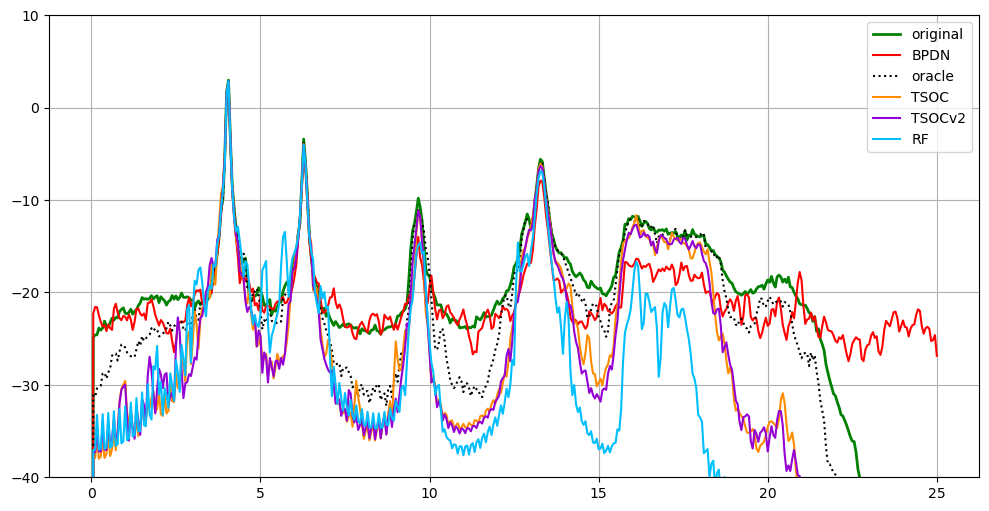

In [39]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(freqs, 10*np.log10(cc_test), label='original', linewidth=2, c='g')
ax.plot(freqs, 10*np.log10(cc_bpdn), label='BPDN', c='r')
ax.plot(freqs, 10*np.log10(cc_oracle), label='oracle', c='k', linestyle='dotted')
ax.plot(freqs, 10*np.log10(cc_tsoc), label='TSOC', c='darkorange')
ax.set(ylim=[-40, 10])
ax.plot(freqs, 10*np.log10(cc_tsoc2), label='TSOCv2', c='darkviolet')
ax.plot(freqs, 10*np.log10(cc_rf), label='RF', c='deepskyblue')

# ax.plot(freqs, 10*np.log10(cc_svm), label='SVM')
ax.grid()
ax.legend()

## Detection

In [40]:
# identify all trained detecors
trained_detectors = os.listdir(detectors_dir)
trained_detectors = [trained_detector for trained_detector in trained_detectors if not 'seedselect' in trained_detector]
trained_detectors = [trained_detector for trained_detector in trained_detectors if 'bridge' in trained_detector]
trained_detectors = [trained_detector for trained_detector in trained_detectors if not 'scaler' in trained_detector]

In [41]:
# parameters of the detector from its name
def parse_detector_parameters(detector_name):
    detector_name = detector_name.split('.pkl')[0]
    params = detector_name.split('_')
    param_dict = {}
    param_dict['detector'] = params[0]
    for param in params[1:]:
        key, value = param.split('=')
        # Attempt to convert to int, float, or keep as string
        if value.isdigit():
            param_dict[key] = int(value)
        else:
            try:
                param_dict[key] = float(value)
            except ValueError:
                # Special case for booleans
                if value.lower() in ['true', 'false']:
                    param_dict[key] = value.lower() == 'true'
                else:
                    param_dict[key] = value

    return param_dict

In [42]:
def load_results(detector_label, parameter_label, kernel=None):
    results = pd.Series(dtype=np.float64)
    for trained_detector in trained_detectors:
        trained_detector = trained_detector.split('bridge_')[1]
        params = parse_detector_parameters(trained_detector)
        
        if not params['detector'] == detector_label:
            continue
        if not params['seedmat'] == seed_matrix:
            continue
        trained_detector = f"{trained_detector.split('.pkl')[0]}"
        param = params[parameter_label]
        if isinstance(param, int):
            param = float(param)
        if params['detector'] == 'OC':
            if params['krn'] != kernel:
                continue
        results_path = os.path.join(results_folder, 'CS', f'bridge_AUC_detector={trained_detector}.pkl')
        if os.path.exists(results_path):
            data = pd.read_pickle(results_path)
            results[param] = data['real']
    return results


In [43]:
def load_estimator_based_results(estimator_type, detector_mode, trained_model):
    trained_model = trained_model.split('bridge-')[1]
    file_name = f'bridge-AUC_detector={trained_model}.pkl'
    if 'TSOC' in estimator_type:
        estimator_type = 'TSOC'
        subfolder = os.path.join(f'{estimator_type}_{mode}', f'alpha={alpha}')
    else:    
        subfolder = f'{estimator_type}_{mode}'
    results_path = os.path.join(results_folder, subfolder, detector_mode, file_name)
    data = pd.read_pickle(results_path)
    return data

## Standard

In [44]:
results_standard = pd.DataFrame(columns=['AUC'], dtype=np.float64)
results_svdd = load_results(detector_label='OC', parameter_label='nu', kernel='rbf')
results_standard.loc['SVDD'] = results_svdd.max()
results_ocsvm = load_results(detector_label='OC', parameter_label='nu', kernel='poly')
results_standard.loc['OC'] = (1-results_ocsvm).max()
results_kde = load_results(detector_label='KDE', parameter_label='bw')
results_standard.loc['KDE'] = results_kde.max()
results_LOF = load_results(detector_label='LOF', parameter_label='neighbors')
results_standard.loc['LOF'] = results_LOF.max()
results_IF = load_results(detector_label='IF', parameter_label='estimators')
results_standard.loc['IF'] = results_IF.max()
result_MD = load_results(detector_label='MD', parameter_label='detector')
results_standard.loc['MD'] = (1-result_MD).max()

In [45]:
results_standard.style.background_gradient(cmap=cmap_auc, vmin=0.5, vmax=1)

,AUC
SVDD,0.830972
OC,0.523104
KDE,0.828048
LOF,0.870959
IF,0.821126
MD,0.847896


In [46]:
m

50

## Estimators

In [74]:
estimators = ['TSOCv1', 'TSOCv2', 'random_forest']
results_estimators = pd.DataFrame(index=detector_modes, columns=estimators, dtype=np.float64)
for detector_mode in detector_modes:
    for estimators_label, model_label in zip(estimators,
                                [model_name, model_name2, model_name_rf]):
        results_estimators.loc[detector_mode, estimators_label] = (1-load_estimator_based_results(estimators_label, detector_mode, model_label)).values[0]

In [75]:
results_estimators.style.background_gradient(cmap=cmap_auc, vmin=0.5, vmax=1)

,TSOCv1,TSOCv2,random_forest
sparsity,0.754075,0.764535,0.764645
self-assessment,0.823381,0.812997,0.872167
self-assessment-complement-MD,0.853392,0.855458,0.854623
self-assessment-complement-MDy,0.856515,0.859007,0.855719
self-assessment-complement-MD-CDF,0.842282,0.841205,0.846341


In [63]:
end

NameError: name 'end' is not defined

## Tuning Estimator

In [ ]:
def compute_rsnr2(x, x_hat, axis=-1):
    ''' Compute Reconstruction Signal-to-Noise Ratio '''
    norm_signal = linalg.norm(x, axis=axis)
    norm_noise = linalg.norm(x - x_hat, axis=axis)
    rsnr = 20 * np.log10(norm_signal / norm_noise)
    return rsnr

def reconstructor(dnn_output, y, A, D, th=0.5):
    ''' Recover the singal based on the oracle prior '''
    B = A @ D
    zhat = dnn_output > th
    BTS = linalg.pinv(B[:, zhat])
    xihat = BTS @ y
    xhat = D[:, zhat] @ xihat
    return xhat


def objective(config, estimator_type):
    
    if estimator_type == 'random_forest':
        # Extract hyperparameters
        n_estimators = int(config["n_estimators"])
        max_depth = config["max_depth"]
        min_samples_split = config["min_samples_split"]
        min_samples_leaf = config["min_samples_leaf"]
        
        # Create the Random Forest classifier
        estimator = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            random_state=42
        )

    elif estimator_type == 'svm':
        # Extract hyperparameters
        C = config["C"]
        kernel = config["kernel"]
        gamma = config["gamma"]

        # Create the SVM classifier
        estimator = SVC(
            C=C,
            kernel=kernel,
            gamma=gamma,
            probability=True,
            random_state=42
        )

    estimator = MultiOutputClassifier(
        make_pipeline(
        StandardScaler(),
        estimator
        )
    )

    # Fit the model
    estimator.fit(Y_train @ B, Z_train.astype(int))
    
    # Make predictions
    Z_hat = estimator.predict(Y_test @ B)
    
    # Decode predictions
    Xhat = np.zeros(Z_hat.shape)
    idx = Z_hat.sum(axis=-1) > 0
    Xhat[idx] = np.array([reconstructor(z, y, A, D, th=0.5) for z, y in zip(Z_hat[idx].astype(bool), Y_test[idx])])
    
    # Compute the custom RSNR metric (higher is better)
    metric = np.mean(compute_rsnr2(X_test, Xhat))
    
    # Ray Tune maximizes the metric, so return the result
    tune.report(rsnr=metric)

# Define the search space for the hyperparameters
search_space ={'random_forest': {
                        "n_estimators": tune.qloguniform(50, 1000, 1), 
                        "max_depth": tune.randint(5, 50),
                        "min_samples_split": tune.choice([2, 5, 10, 20]),
                        "min_samples_leaf": tune.choice([1, 2, 4, 8]),
                        "max_features": tune.choice([None, "sqrt", "log2"]),
                        "bootstrap": tune.choice([True, False]),
                        "criterion": tune.choice(["gini", "entropy"]),
                        },
                'svm': {
                        "C": tune.loguniform(0.1, 1000),
                        "kernel": tune.choice(["linear", "poly", "rbf", "sigmoid"]),
                        "gamma": tune.choice(["scale", "auto"]),
                        }
}



In [62]:
estimator_type = 'random_forest'
# Run the Ray Tune experiment
analysis = tune.run(
    lambda config: objective(config, estimator_type),
    config=search_space[estimator_type], 
    num_samples=1000,  # Number of different configurations to try
    resources_per_trial={"cpu": 1}, 
    metric="rsnr",  # Metric to optimize
    mode="max",  # maximize RSNR
    verbose=1
)

# Get the best configuration
print("Best hyperparameters found were: ", analysis.best_config)

Trial name,# failures,error file
lambda_5a661_00000,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00000_0_bootstrap=True,criterion=gini,max_depth=29,max_features=None,min_samples_leaf=8,min_samples_split=10,n_estima_2025-04-23_16-00-53/error.txt"
lambda_5a661_00001,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00001_1_bootstrap=True,criterion=gini,max_depth=42,max_features=sqrt,min_samples_leaf=8,min_samples_split=2,n_estimat_2025-04-23_16-00-54/error.txt"
lambda_5a661_00002,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00002_2_bootstrap=True,criterion=gini,max_depth=31,max_features=sqrt,min_samples_leaf=4,min_samples_split=5,n_estimat_2025-04-23_16-00-54/error.txt"
lambda_5a661_00004,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00004_4_bootstrap=True,criterion=entropy,max_depth=8,max_features=None,min_samples_leaf=4,min_samples_split=2,n_estim_2025-04-23_16-00-54/error.txt"
lambda_5a661_00006,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00006_6_bootstrap=False,criterion=entropy,max_depth=30,max_features=sqrt,min_samples_leaf=1,min_samples_split=20,n_es_2025-04-23_16-00-54/error.txt"
lambda_5a661_00011,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00011_11_bootstrap=True,criterion=gini,max_depth=28,max_features=sqrt,min_samples_leaf=4,min_samples_split=5,n_estima_2025-04-23_16-00-55/error.txt"
lambda_5a661_00013,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00013_13_bootstrap=True,criterion=gini,max_depth=17,max_features=None,min_samples_leaf=2,min_samples_split=2,n_estima_2025-04-23_16-00-55/error.txt"
lambda_5a661_00014,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00014_14_bootstrap=False,criterion=entropy,max_depth=20,max_features=None,min_samples_leaf=4,min_samples_split=2,n_es_2025-04-23_16-00-55/error.txt"
lambda_5a661_00022,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00022_22_bootstrap=False,criterion=entropy,max_depth=21,max_features=log2,min_samples_leaf=4,min_samples_split=10,n_e_2025-04-23_16-00-56/error.txt"
lambda_5a661_00024,1,"/home/andriyenttsel/ray_results/lambda_2025-04-23_16-00-45/lambda_5a661_00024_24_bootstrap=False,criterion=gini,max_depth=15,max_features=sqrt,min_samples_leaf=1,min_samples_split=5,n_estim_2025-04-23_16-00-56/error.txt"


(<lambda> pid=4168838) 2025-04-23 16:11:33,541	ERROR worker.py:432 -- SystemExit was raised from the worker.
(<lambda> pid=4168838) Traceback (most recent call last):
(<lambda> pid=4168838)   File "python/ray/_raylet.pyx", line 770, in ray._raylet.task_execution_handler
(<lambda> pid=4168838)   File "python/ray/_raylet.pyx", line 591, in ray._raylet.execute_task
(<lambda> pid=4168838)   File "python/ray/_raylet.pyx", line 629, in ray._raylet.execute_task
(<lambda> pid=4168838)   File "python/ray/_raylet.pyx", line 636, in ray._raylet.execute_task
(<lambda> pid=4168838)   File "python/ray/_raylet.pyx", line 640, in ray._raylet.execute_task
(<lambda> pid=4168838)   File "python/ray/_raylet.pyx", line 589, in ray._raylet.execute_task.function_executor
(<lambda> pid=4168838)   File "/home/andriyenttsel/miniconda3/envs/dnncs/lib/python3.9/site-packages/ray/_private/function_manager.py", line 639, in actor_method_executor
(<lambda> pid=4168838)     return method(__ray_actor, *args, **kwargs)

Best hyperparameters found were:  {'n_estimators': 90.0, 'max_depth': 6, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'bootstrap': True, 'criterion': 'gini'}


In [37]:
end

NameError: name 'end' is not defined

In [ ]:
O_ko = tsoc(torch.from_numpy(Y_ko).float().to(device))
O_ko = O_ko.cpu().detach().numpy() 
# 
Zhat = O_ko > threshold
Xhat_ko_tsoc = np.zeros(Zhat.shape)
idx_tsoc = Zhat.sum(axis=-1) > 0
Xhat_ko_tsoc[idx_tsoc] = cs.decode(list(zip(Y_ko[idx_tsoc], Zhat[idx_tsoc])))
Yhat_ok_tsoc  = cs.encode(Xhat_tsoc)
Yhat_ko_tsoc  = cs.encode(Xhat_ko_tsoc)
score_ok_tsoc = np.sum((Y_test - Yhat_ok_tsoc)**2, axis=-1)
score_ko_tsoc = np.sum((Y_ko - Yhat_ko_tsoc)**2, axis=-1)
score_ok_tsoc = score_ok_tsoc[:len(score_ko_tsoc)]
label = np.concatenate([np.zeros(len(score_ok_tsoc)), np.ones(len(score_ko_tsoc))])
scores_tsoc = np.concatenate([score_ok_tsoc, score_ko_tsoc])
roc_auc_score(label, scores_tsoc)

0.8266373966942149

In [ ]:
O_ko = tsoc2(torch.from_numpy(Y_ko @ B).float().to(device))
O_ko = O_ko.cpu().detach().numpy() 
# 
Zhat = O_ko > threshold
Xhat_ko_tsoc2 = np.zeros(Zhat.shape)
idx_tsoc = Zhat.sum(axis=-1) > 0
Xhat_ko_tsoc2[idx_tsoc] = cs.decode(list(zip(Y_ko[idx_tsoc], Zhat[idx_tsoc])))
Yhat_ok_tsoc2  = cs.encode(Xhat_tsoc2)
Yhat_ko_tsoc2 = cs.encode(Xhat_ko_tsoc2)
score_ok_tsoc2 = np.sum((Y_test - Yhat_ok_tsoc2)**2, axis=-1)
score_ko_tsoc2 = np.sum((Y_ko - Yhat_ko_tsoc2)**2, axis=-1)
score_ok_tsoc2 = score_ok_tsoc2[:len(score_ko_tsoc2)]
label = np.concatenate([np.zeros(len(score_ok_tsoc2)), np.ones(len(score_ko_tsoc2))])
scores_tsoc2 = np.concatenate([score_ok_tsoc2, score_ko_tsoc2])
roc_auc_score(label, scores_tsoc2)

0.8336893078512396

In [ ]:
O_ko = random_forest.predict(Y_ko @ B)
# 
Zhat = O_ko > threshold
Xhat_ko_rf= np.zeros(Zhat.shape)
idx_rf = Zhat.sum(axis=-1) > 0
Xhat_ko_rf[idx_rf] = cs.decode(list(zip(Y_ko[idx_rf], Zhat[idx_rf])))
Yhat_ok_rf  = cs.encode(Xhat_rf)
Yhat_ko_rf = cs.encode(Xhat_ko_rf)
score_ok_rf = np.sum((Y_test - Yhat_ok_rf)**2, axis=-1)
score_ko_rf = np.sum((Y_ko - Yhat_ko_rf)**2, axis=-1)
score_ok_rf = score_ok_rf[:len(score_ko_rf)]
label = np.concatenate([np.zeros(len(score_ok_rf)), np.ones(len(score_ko_rf))])
scores_rf = np.concatenate([score_ok_rf, score_ko_rf])
roc_auc_score(label, scores_rf)

0.8621410123966943

In [ ]:
1-load_estimator_based_results('random_forest', 'sparsity', model_name_rf)

real    0.694316
dtype: float64

In [ ]:
1-load_estimator_based_results('random_forest', 'self-assessment', model_name_rf)

real    0.862141
dtype: float64

In [ ]:
1-load_estimator_based_results('random_forest', 'self-assessment-complement-MD', model_name_rf)

real    0.837571
dtype: float64

In [ ]:
1-load_estimator_based_results('random_forest', 'self-assessment-complement-MDy', model_name_rf)

real    0.840811
dtype: float64

In [ ]:
1-load_estimator_based_results('random_forest', 'self-assessment-complement-MD-CDF', model_name_rf)

real    0.84265
dtype: float64

In [ ]:
freqs, coeff_ko, cc_ko = estimate_spectrum(n, fs, X_ko, K=K, resolution=K, method='welch')

In [ ]:
freqs, coeff_ko, cc_ko = estimate_spectrum(n, fs, X_ko, K=K, resolution=K, method='welch')
freqs, coeff_ko_tsoc, cc_ko_tsoc = estimate_spectrum(n, fs, Xhat_ko_tsoc, K=K, resolution=K, method='welch')
freqs, coeff_ko_tsoc2, cc_ko_tsoc2 = estimate_spectrum(n, fs, Xhat_ko_tsoc2, K=K, resolution=K, method='welch')
freqs, coeff_ko_rf, cc_ko_rf = estimate_spectrum(n, fs, Xhat_ko_rf, K=K, resolution=K, method='welch')

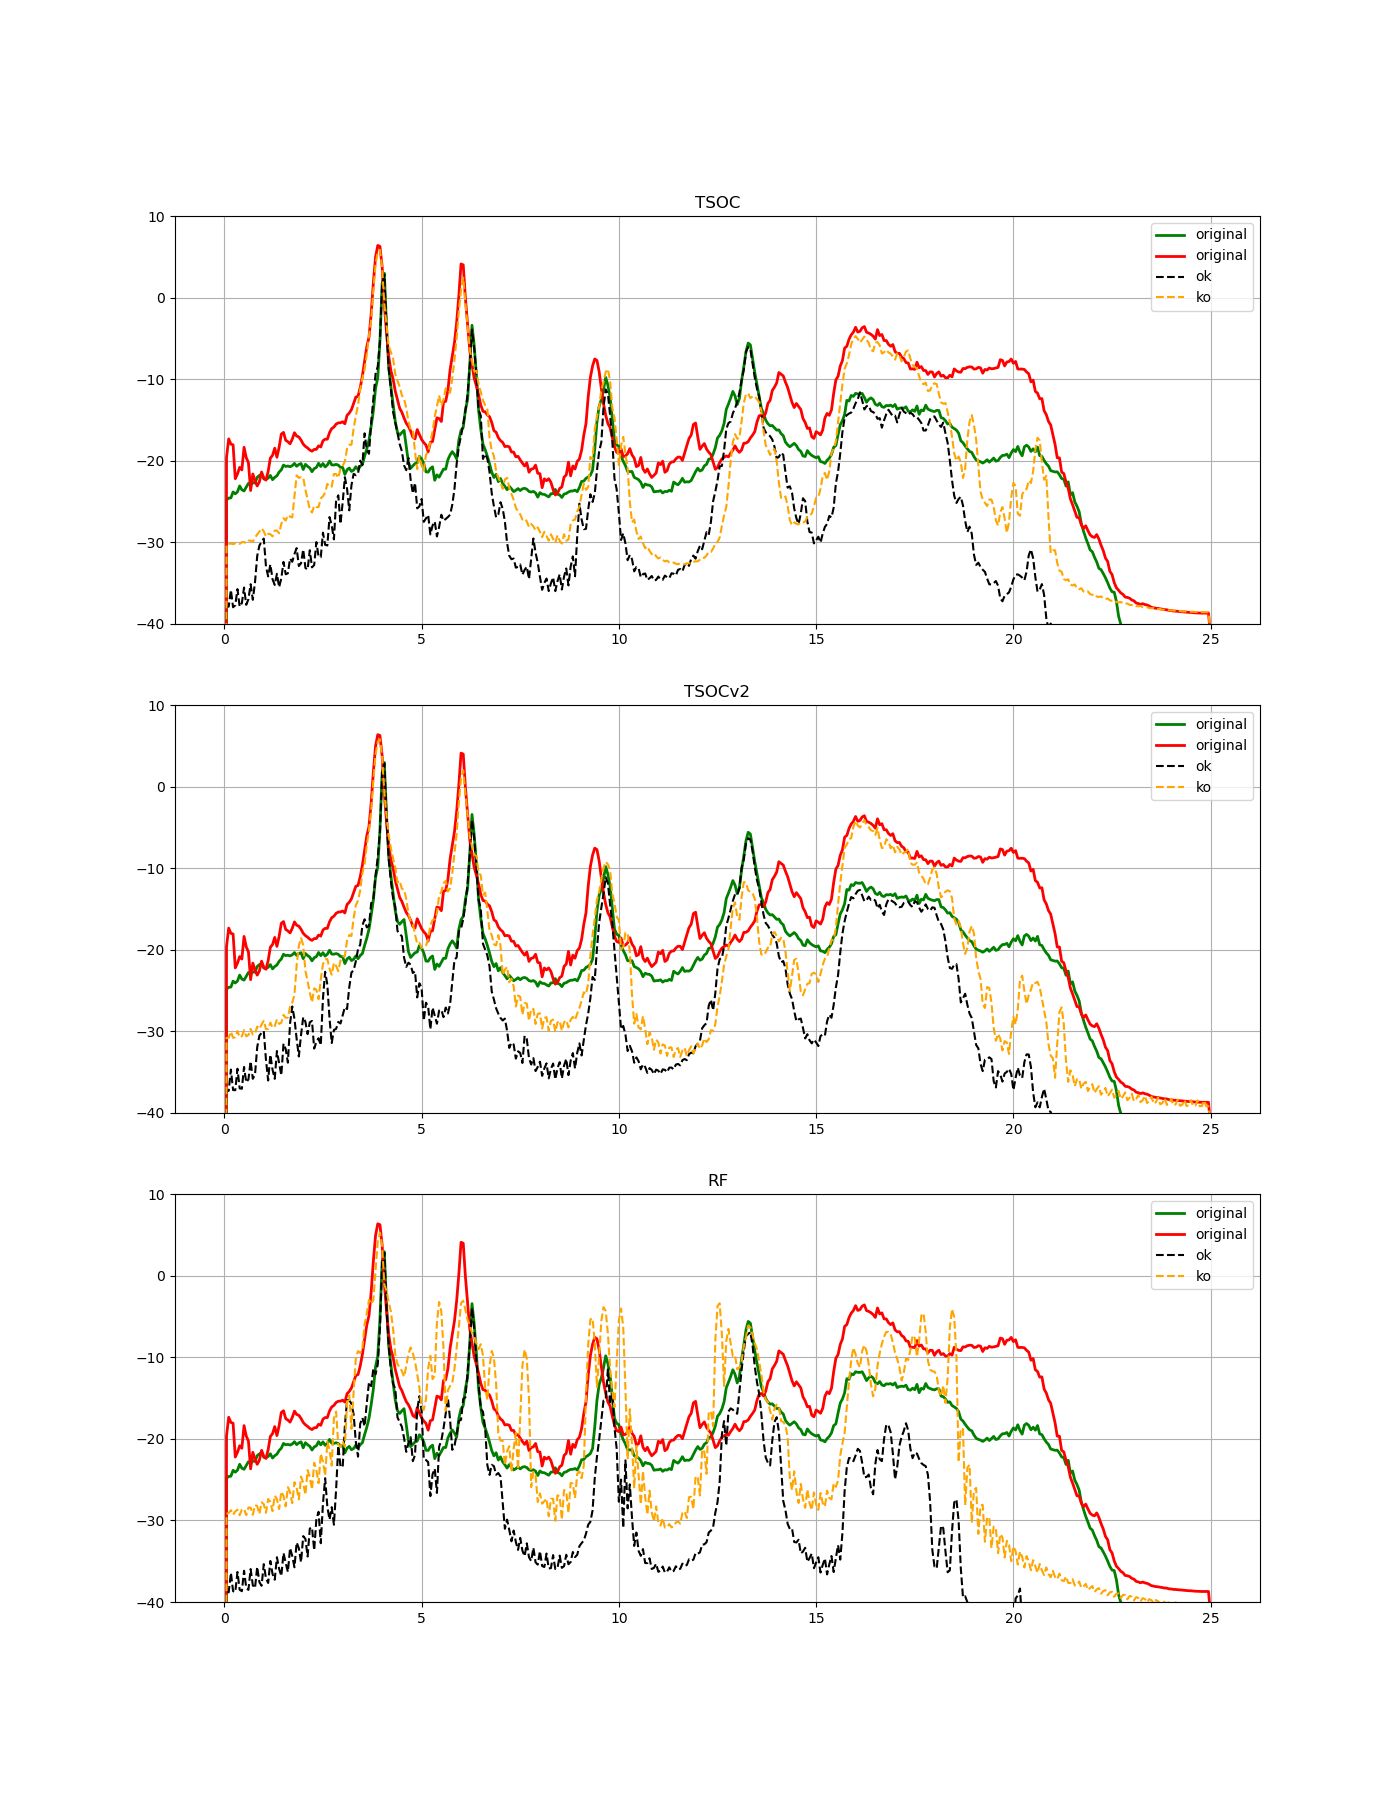

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(14, 18))
ax[0].plot(freqs, 10*np.log10(cc_test), label='original', linewidth=2, c='g')
ax[0].plot(freqs, 10*np.log10(cc_ko), label='original', linewidth=2, c='r')
ax[0].plot(freqs, 10*np.log10(cc_tsoc), label='ok', c='k', linestyle='dashed')
ax[0].plot(freqs, 10*np.log10(cc_ko_tsoc), label='ko', c='orange', linestyle='dashed')
ax[0].grid()
ax[0].set(title='TSOC')
ax[0].set(ylim=[-40, 10])
ax[0].legend()

ax[1].plot(freqs, 10*np.log10(cc_test), label='original', linewidth=2, c='g')
ax[1].plot(freqs, 10*np.log10(cc_ko), label='original', linewidth=2, c='r')
ax[1].plot(freqs, 10*np.log10(cc_tsoc2), label='ok', c='k', linestyle='dashed')
ax[1].plot(freqs, 10*np.log10(cc_ko_tsoc2), label='ko', c='orange', linestyle='dashed')
ax[1].grid()
ax[1].set(title='TSOCv2')
ax[1].set(ylim=[-40, 10])
ax[1].legend()

ax[2].plot(freqs, 10*np.log10(cc_test), label='original', linewidth=2, c='g')
ax[2].plot(freqs, 10*np.log10(cc_ko), label='original', linewidth=2, c='r')
ax[2].plot(freqs, 10*np.log10(cc_rf), label='ok', c='k', linestyle='dashed')
ax[2].plot(freqs, 10*np.log10(cc_ko_rf), label='ko', c='orange', linestyle='dashed')
ax[2].grid()
ax[2].set(title='RF')
ax[2].set(ylim=[-40, 10])
ax[2].legend()



### MD

In [ ]:
scaler = StandardScaler(with_std=False).fit(Y_train)
mahal = MD().fit(scaler.transform(Y_train))
1-mahal.test(np.concatenate([scaler.transform(Y_test[:len(Y_ko)]), scaler.transform(Y_ko)]), metric='AUC')

0.8478964359504132

### MSISSD

In [ ]:
O = tsoc(torch.from_numpy(Y_train).float().to(device))
O = O.cpu().detach().numpy() 
# 
Zhat = O > threshold
Xhat_train_tsoc = np.zeros(Zhat.shape)
idx_tsoc = Zhat.sum(axis=-1) > 0
Xhat_train_tsoc[idx_tsoc] = cs.decode(list(zip(Y_train[idx_tsoc], Zhat[idx_tsoc])))


O = tsoc2(torch.from_numpy(Y_train @ B).float().to(device))
O = O.cpu().detach().numpy() 
# 
Zhat = O > threshold
Xhat_train_tsoc2 = np.zeros(Zhat.shape)
idx_tsoc = Zhat.sum(axis=-1) > 0
Xhat_train_tsoc2[idx_tsoc] = cs.decode(list(zip(Y_train[idx_tsoc], Zhat[idx_tsoc])))

In [ ]:
freqs, coeff_train_tsoc, cc_train_tsoc = estimate_spectrum(n, fs, Xhat_train_tsoc, K=1, resolution=1, method='welch')
freqs, coeff_ok_tsoc, cc_ok_tsoc = estimate_spectrum(n, fs, Xhat_tsoc, K=1, resolution=1, method='welch')
freqs, coeff_ko_tsoc, cc_ko_tsoc = estimate_spectrum(n, fs, Xhat_ko_tsoc, K=1, resolution=1, method='welch')

freqs, coeff_train_tsoc2, cc_train_tsoc2 = estimate_spectrum(n, fs, Xhat_train_tsoc2, K=1, resolution=1, method='welch')
freqs, coeff_ok_tsoc2, cc_ok_tsoc2 = estimate_spectrum(n, fs, Xhat_tsoc2, K=1, resolution=1, method='welch')
freqs, coeff_ko_tsoc2, cc_ko_tsoc2 = estimate_spectrum(n, fs, Xhat_ko_tsoc2, K=1, resolution=1, method='welch')

In [ ]:
# SISSD over whole spectrum
scoreok = np.array(
    [
        MSISSD(cc_train_tsoc, cc, [(freqs.min(), freqs.max())], freqs, eps=1e-7) 
        for cc in coeff_ok_tsoc
    ]
)[:, 0]

scoreko = np.array(
    [
        MSISSD(cc_train_tsoc, cc, [(freqs.min(), freqs.max())], freqs, eps=1e-7) 
        for cc in coeff_ko_tsoc
    ]
)[:, 0]

scoreok = scoreok[:len(scoreko)]
scores_allmsissd = np.concatenate([scoreok, scoreko])
label = np.concatenate([np.zeros(len(scoreok)), np.ones(len(scoreko))])
1-roc_auc_score(label, scores_allmsissd)

0.7170538481404959

In [ ]:
# SISSD over whole spectrum
scoreok = np.array(
    [
        MSISSD(cc_train_tsoc2, cc, [(freqs.min(), freqs.max())], freqs, eps=1e-7) 
        for cc in coeff_ok_tsoc2
    ]
)[:, 0]

scoreko = np.array(
    [
        MSISSD(cc_train_tsoc2, cc, [(freqs.min(), freqs.max())], freqs, eps=1e-7) 
        for cc in coeff_ko_tsoc2
    ]
)[:, 0]
scoreok = scoreok[:len(scoreko)]
scores_allmsissd = np.concatenate([scoreok, scoreko])
label = np.concatenate([np.zeros(len(scoreok)), np.ones(len(scoreko))])
1-roc_auc_score(label, scores_allmsissd)

0.7155940082644627

In [ ]:
end

NameError: name 'end' is not defined

In [ ]:
def parse_neural_parameters(model_name, detector_type='TSOC'):
    model_name = model_name.split('.pth')[0]
    model_name = model_name.split(f'{detector_type}-')[1]
    params = model_name.split('_')
    param_dict = {}
    for param in params:
        key, value = param.split('=')
        # Attempt to convert to int, float, or keep as string
        if value.isdigit():
            param_dict[key] = int(value)
        else:
            try:
                param_dict[key] = float(value)
            except ValueError:
                # Special case for booleans
                if value.lower() in ['true', 'false']:
                    param_dict[key] = value.lower() == 'true'
                else:
                    param_dict[key] = value

    return param_dict

In [ ]:
def load_results(detector_label, parameter_label, kernel=None):
    results = pd.Series(dtype=np.float64)
    for trained_detector in trained_detectors:
        trained_detector = trained_detector.split('bridge_')[1]
        params = parse_detector_parameters(trained_detector)
        
        if not params['detector'] == detector_label:
            continue
        if not params['seedmat'] == seed_matrix:
            continue
        trained_detector = f"{trained_detector.split('.pkl')[0]}"
        param = params[parameter_label]
        if isinstance(param, int):
            param = float(param)
        if params['detector'] == 'OC':
            if params['krn'] != kernel:
                continue
        results_path = os.path.join(results_folder, 'CS', f'bridge_AUC_detector={trained_detector}.pkl')
        if os.path.exists(results_path):
            data = pd.read_pickle(results_path)
            results[param] = data['real']
    return results


In [ ]:
def load_tsoc_based_results(detector_mode, trained_model, version):
    if version == 'v1':
        architecture = 'TSOC'
    elif version == 'v2':
        architecture = 'TSOCv2'
    trained_model = trained_model.split('bridge-')[1]
    params = parse_neural_parameters(trained_model, architecture)
    if params['seedmatrix'] == seed_matrix:
        trained_model = f"{trained_model.split('.pth')[0]}"
        results_subfolder = f'TSOC_{mode}'
        file_name = f'bridge-AUC_detector={trained_model}.pkl'
        results_path = os.path.join(results_folder, results_subfolder, f'alpha={alpha}', detector_mode, file_name)
        if os.path.exists(results_path):
            data = pd.read_pickle(results_path)
    return data

In [ ]:
detector_mode = 'sparsity'
results_sparsity = load_tsoc_based_results(detector_mode, model_name, 'v1')
1-results_sparsity

real    0.736241
dtype: float64

In [ ]:
detector_mode = 'self-assessment'
results_sa = load_tsoc_based_results(detector_mode, model_name, 'v1')
1-results_sa

real    0.826637
dtype: float64

In [ ]:
detector_mode = 'self-assessment-complement-MD'
results_sum = load_tsoc_based_results(detector_mode, model_name, 'v1')
1-results_sum

real    0.83984
dtype: float64

In [ ]:
detector_mode = 'self-assessment-complement-MDy'
results_sum = load_tsoc_based_results(detector_mode, model_name, 'v1')
1-results_sum

real    0.842789
dtype: float64

In [ ]:
detector_mode = 'self-assessment-complement-MD-CDF'
results_cdf = load_tsoc_based_results(detector_mode, model_name, 'v1')
1-results_cdf

real    0.829148
dtype: float64

## TSOCv2

In [ ]:
detector_mode = 'sparsity'
results_sparsity = load_tsoc_based_results(detector_mode, model_name2, 'v2')
1-results_sparsity

real    0.71567
dtype: float64

In [ ]:
detector_mode = 'self-assessment'
results_sa = load_tsoc_based_results(detector_mode, model_name2, 'v2')
1-results_sa

real    0.833689
dtype: float64

In [ ]:
detector_mode = 'self-assessment-complement-MD'
results_sum = load_tsoc_based_results(detector_mode, model_name2, 'v2')
1-results_sum

real    0.83384
dtype: float64

In [ ]:
detector_mode = 'self-assessment-complement-MDy'
results_sum = load_tsoc_based_results(detector_mode, model_name2, 'v2')
1-results_sum

real    0.838018
dtype: float64

In [ ]:
detector_mode = 'self-assessment-complement-MD-CDF'
results_cdf = load_tsoc_based_results(detector_mode, model_name2, 'v2')
1-results_cdf

real    0.827726
dtype: float64

In [ ]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(freqs, 10*np.log10(cc_test), label='original', linewidth=2, c='k')
ax.plot(freqs, 10*np.log10(cc_tsoc), label='ok', c='g')
ax.plot(freqs, 10*np.log10(cc_ko_tsoc), label='ko', c='r')
# ax.plot(freqs, 10*np.log10(cc_tsoc2), label='TSOCv2', c='darkviolet')
# ax.plot(freqs, 10*np.log10(cc_rf), label='RF', c='deepskyblue')

# ax.plot(freqs, 10*np.log10(cc_svm), label='SVM')
ax.grid()
ax.legend()

In [ ]:
methods = ['k_neighbors', 'random_forest', 'logistic_regression', 'SVM', 'naive_bayes', 'Sparse SVM']
methods = ['random_forest']
result = pd.DataFrame(columns=['RSNR', 'Accuracy'], dtype=np.float64)
for method_ in methods:
    Zhat, Xhat = train_pred(Y_train, Y_test, Z_train, 'Y', method_)
    result.loc[method, 'Accuracy'] = accuracy_score(Z_test, Zhat)
    result.loc[method, 'RSNR'] = np.mean(compute_rsnr(X_test, Xhat))


Intel MKL ERROR: Parameter 10 was incorrect on entry to DGESDD.


ValueError: Internal work array size computation failed: -10

: 

: 

In [ ]:
result

,RSNR,Accuracy
TSOC,-3.356804,0.0


: 

: 

## Reference

In [ ]:
Xh_test = cs.decode(list(zip(Y_test, Z_test)))
result.loc['SO', 'RSNR'] = np.mean(compute_rsnr(X, Xh_test))
result.loc['SO', 'Accuracy'] = 1

: 

: 

In [ ]:
bpdn = BasisPursuitDenoise(B, D, sigma=1e-4, processes=processes)
Xh_bpdn = bpdn.decode(Y_test)
result.loc['BPDN', 'RSNR'] = np.mean(compute_rsnr(X_test, Xh_bpdn))

Linesearch failed with error 1. Damping max BB scaling to 10000.0
Linesearch failed with error 1. Damping max BB scaling to 10000.0
Linesearch failed with error 1. Damping max BB scaling to 10000.0
Linesearch failed with error 1. Damping max BB scaling to 1000.0
Linesearch failed with error 1. Damping max BB scaling to 10000.0
Linesearch failed with error 1. Damping max BB scaling to 1000.0
Linesearch failed with error 1. Damping max BB scaling to 10000.0
Linesearch failed with error 1. Damping max BB scaling to 1000.0
Linesearch failed with error 1. Damping max BB scaling to 10000.0


: 

: 

: 

: 